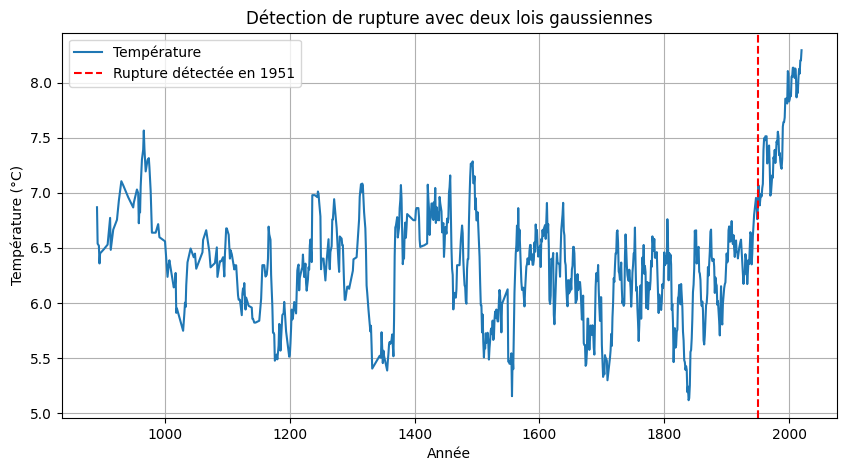

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

df = pd.read_csv("Japan.csv")
annees = df["Year"].values
temperatures = df["Temp_Japon"].values

mask = ~np.isnan(temperatures)
annees = annees[mask]
temperatures = temperatures[mask]

# Fonction de détection de rupture
def detection_rupture_gaussienne(annees, valeurs):
    n = len(valeurs)
    best_index = None
    best_score = -np.inf

    for i in range(10, n - 10):  # éviter les bords
        segment1 = valeurs[:i]
        segment2 = valeurs[i:]

        mu1, std1 = np.mean(segment1), np.std(segment1)
        mu2, std2 = np.mean(segment2), np.std(segment2)

        log_like1 = np.sum(norm.logpdf(segment1, mu1, std1))
        log_like2 = np.sum(norm.logpdf(segment2, mu2, std2))

        total_log_like = log_like1 + log_like2

        if total_log_like > best_score:
            best_score = total_log_like
            best_index = i

    rupture_year = annees[best_index]
    return rupture_year, best_index

rupture_year, rupture_index = detection_rupture_gaussienne(annees, temperatures)

plt.figure(figsize=(10, 5))
plt.plot(annees, temperatures, label="Température")
plt.axvline(x=rupture_year, color='r', linestyle='--', label=f"Rupture détectée en {rupture_year}")
plt.xlabel("Année")
plt.ylabel("Température (°C)")
plt.title("Détection de rupture avec deux lois gaussiennes")
plt.legend()
plt.grid(True)
plt.show()

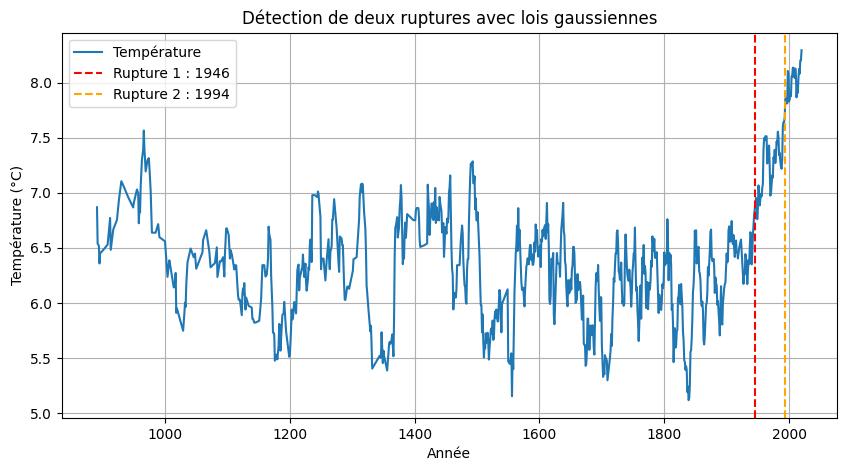

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

df = pd.read_csv("Japan.csv")
annees = df["Year"].values
temperatures = df["Temp_Japon"].values

mask = ~np.isnan(temperatures)
annees = annees[mask]
temperatures = temperatures[mask]

def detection_deux_ruptures_gaussiennes(annees, valeurs):
    n = len(valeurs)
    best_score = -np.inf
    best_t1, best_t2 = None, None

    for t1 in range(10, n - 20):  # laisser au moins 10 points par segment
        for t2 in range(t1 + 10, n - 10):
            seg1 = valeurs[:t1]
            seg2 = valeurs[t1:t2]
            seg3 = valeurs[t2:]

            mu1, std1 = np.mean(seg1), np.std(seg1)
            mu2, std2 = np.mean(seg2), np.std(seg2)
            mu3, std3 = np.mean(seg3), np.std(seg3)

            loglike1 = np.sum(norm.logpdf(seg1, mu1, std1))
            loglike2 = np.sum(norm.logpdf(seg2, mu2, std2))
            loglike3 = np.sum(norm.logpdf(seg3, mu3, std3))

            total_score = loglike1 + loglike2 + loglike3

            if total_score > best_score:
                best_score = total_score
                best_t1, best_t2 = t1, t2

    return annees[best_t1], annees[best_t2], best_t1, best_t2

grupture1, rupture2, i1, i2 = detection_deux_ruptures_gaussiennes(annees, temperatures)

# Affichage
plt.figure(figsize=(10, 5))
plt.plot(annees, temperatures, label="Température")
plt.axvline(x=rupture1, color='r', linestyle='--', label=f"Rupture 1 : {rupture1}")
plt.axvline(x=rupture2, color='orange', linestyle='--', label=f"Rupture 2 : {rupture2}")
plt.xlabel("Année")
plt.ylabel("Température (°C)")
plt.title("Détection de deux ruptures avec lois gaussiennes")
plt.legend()
plt.grid(True)
plt.show()

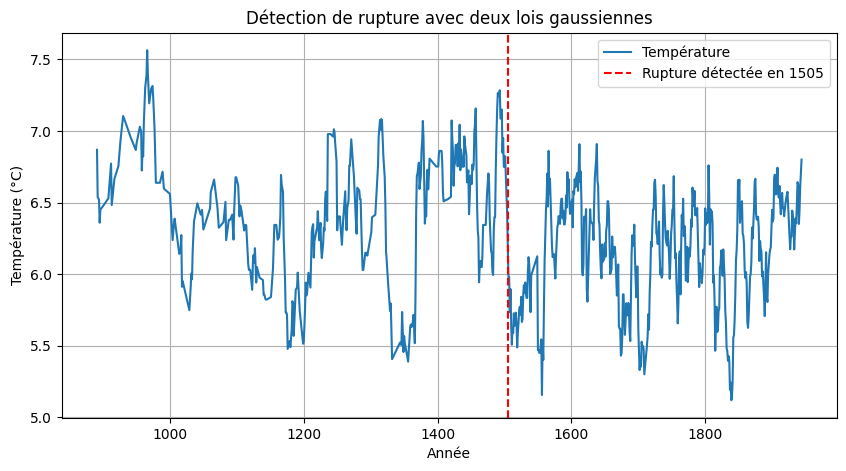

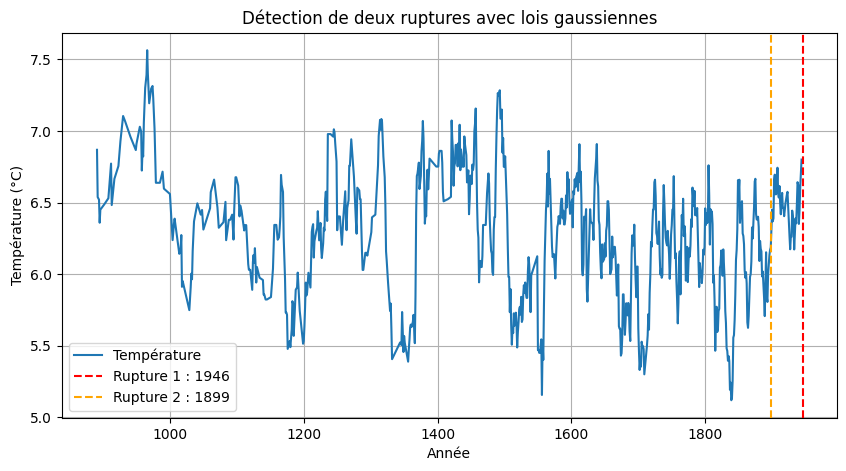

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

df = pd.read_csv("Japan2.csv")
annees = df["Year"].values
temperatures = df["Temp_Japon"].values

mask = ~np.isnan(temperatures)
annees = annees[mask]
temperatures = temperatures[mask]

# Fonction de détection de rupture
def detection_rupture_gaussienne(annees, valeurs):
    n = len(valeurs)
    best_index = None
    best_score = -np.inf

    for i in range(10, n - 10):  # éviter les bords
        segment1 = valeurs[:i]
        segment2 = valeurs[i:]

        mu1, std1 = np.mean(segment1), np.std(segment1)
        mu2, std2 = np.mean(segment2), np.std(segment2)

        log_like1 = np.sum(norm.logpdf(segment1, mu1, std1))
        log_like2 = np.sum(norm.logpdf(segment2, mu2, std2))

        total_log_like = log_like1 + log_like2

        if total_log_like > best_score:
            best_score = total_log_like
            best_index = i

    rupture_year = annees[best_index]
    return rupture_year, best_index

rupture_year, rupture_index = detection_rupture_gaussienne(annees, temperatures)

plt.figure(figsize=(10, 5))
plt.plot(annees, temperatures, label="Température")
plt.axvline(x=rupture_year, color='r', linestyle='--', label=f"Rupture détectée en {rupture_year}")
plt.xlabel("Année")
plt.ylabel("Température (°C)")
plt.title("Détection de rupture avec deux lois gaussiennes")
plt.legend()
plt.grid(True)
plt.show()

df = pd.read_csv("Japan2.csv")
annees = df["Year"].values
temperatures = df["Temp_Japon"].values

mask = ~np.isnan(temperatures)
annees = annees[mask]
temperatures = temperatures[mask]

def detection_deux_ruptures_gaussiennes(annees, valeurs):
    n = len(valeurs)
    best_score = -np.inf
    best_t1, best_t2 = None, None

    for t1 in range(10, n - 20):  # laisser au moins 10 points par segment
        for t2 in range(t1 + 10, n - 10):
            seg1 = valeurs[:t1]
            seg2 = valeurs[t1:t2]
            seg3 = valeurs[t2:]

            mu1, std1 = np.mean(seg1), np.std(seg1)
            mu2, std2 = np.mean(seg2), np.std(seg2)
            mu3, std3 = np.mean(seg3), np.std(seg3)

            loglike1 = np.sum(norm.logpdf(seg1, mu1, std1))
            loglike2 = np.sum(norm.logpdf(seg2, mu2, std2))
            loglike3 = np.sum(norm.logpdf(seg3, mu3, std3))

            total_score = loglike1 + loglike2 + loglike3

            if total_score > best_score:
                best_score = total_score
                best_t1, best_t2 = t1, t2

    return annees[best_t1], annees[best_t2], best_t1, best_t2

grupture1, rupture2, i1, i2 = detection_deux_ruptures_gaussiennes(annees, temperatures)

# Affichage
plt.figure(figsize=(10, 5))
plt.plot(annees, temperatures, label="Température")
plt.axvline(x=rupture1, color='r', linestyle='--', label=f"Rupture 1 : {rupture1}")
plt.axvline(x=rupture2, color='orange', linestyle='--', label=f"Rupture 2 : {rupture2}")
plt.xlabel("Année")
plt.ylabel("Température (°C)")
plt.title("Détection de deux ruptures avec lois gaussiennes")
plt.legend()
plt.grid(True)
plt.show()